# Sri Lanka Dengue Early-Warning (district level): Random Forest vs XGBoost
**Task:** For every district and week, will the dengue incidence **two weeks from now** be a *high week for that district*?  
**Data:** `dengue_srilanka_full_2006_2025.csv`, 25 districts × 991 weeks (Dec 2006 – Dec 2025), 24,775 rows: cases, population, geography, rainfall, temperature, humidity.  
**Core question:** how do **Random Forest** and **XGBoost** compare, in accuracy, behaviour, agreement and explanations, and can both be served side by side in a web app?  
**Also included:** soft voting (RF+XGB), logistic regression and persistence baselines, climate ablation, SHAP, single-sample inference, `.pkl` export, Streamlit app.

### Where each requirement is covered
| Requirement | Section |
|---|---|
| Local Sri Lankan dataset, domain understanding | 2, 3 |
| Null / type / duplicate checks, imputation, transformation, scaling, **leakage control** | 3, 4 |
| Proper data analysis before modelling | 5 |
| RF and XGBoost with **designed, non-default** hyper-parameters | 8 |
| **RF vs XGBoost comparison** (metrics, ROC/PR, calibration, agreement, significance, per district / year, matched operating points) | 9 |
| Comparison with existing approaches (persistence, logistic regression) and soft voting | 8, 9 |
| SHAP explanations of both models | 10 |
| Single-sample inference on left-out data (**both models predict**) and `.pkl` files | 11, 12 |
| GenAI front end (Streamlit, shows both predictions + comparison) | `streamlit_app.py`, `prompts/` |

## 1. Setup

In [1]:
import sys, json, time, pickle, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd() if (Path.cwd() / "dengue_sl.py").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV, GridSearchCV
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import calibration_curve
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss, accuracy_score, precision_score,
                             recall_score, f1_score, roc_curve, precision_recall_curve, ConfusionMatrixDisplay)
from xgboost import XGBClassifier
import shap

import dengue_sl as dsl
from dengue_sl import add_derived, RAW_FIELDS, DYNAMIC, STATIC, CLIMATE_FIELDS, HORIZON

SEED = 42
np.random.seed(SEED)
FIG = ROOT / "figures"; FIG.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook"); plt.rcParams["figure.dpi"] = 110
RF_C, XG_C = "#2a6db3", "#b3402a"      # colour code used everywhere: Random Forest = blue, XGBoost = red
print("root:", ROOT)

root: /home/claude/dengue2


## 2. Problem definition and domain context
**Why this matters.** Dengue is Sri Lanka's most important mosquito-borne disease. Control (fogging, breeding-site clean-up, hospital bed planning) is organised **by district**, and needs lead time, so the model predicts **two weeks ahead**.

**Why a relative target.** District incidence differs by more than 100× (Colombo vs Mullaitivu), and the file spans 2007–2025 with growing reporting. A single national threshold would flag Colombo/Gampaha every week and Mullaitivu never. So a **high week = incidence two weeks ahead above that district's own 75th percentile of the training period**, which is how endemic-channel alert thresholds work in practice.

**Inputs at week *t* (all available in real time):** last 4 weeks of cases, rainfall (this week, 4- and 8-week means), 4-week mean max/min temperature and humidity, week of year (cyclic), and district attributes (population, latitude/longitude, coast, elevation, the district's 'high' level).

**Domain knowledge used.** (i) *Aedes* breeding follows rainfall with a lag of several weeks, so climate enters as rolling means; (ii) Sri Lanka's two monsoons make season cyclic; (iii) districts differ in population, so counts become incidence per 100,000; (iv) epidemic waves are shared across districts, so recent local incidence relative to the local baseline is the natural signal.

## 3. Data collection and audit
Panel data: **25 districts × 991 weekly records** (Dec 2006 – Dec 2025). Before modelling I audit types, nulls, duplicates, calendar continuity, derived columns and implausible values.

In [2]:
DATA = ROOT / "data" / "dengue_srilanka_full_2006_2025.csv"
raw = pd.read_csv(DATA)
print("shape:", raw.shape, "| districts:", raw.district.nunique(), "| weeks:", raw["start.date"].nunique())
display(raw.head(3).T)
nulls = raw.isna().sum(); print("\nnulls:\n" + nulls[nulls > 0].to_string())
print("\nduplicate (district, week):", raw.duplicated(["district", "start.date"]).sum())
d = pd.to_datetime(raw["start.date"]).drop_duplicates().sort_values().diff().dt.days.value_counts()
print("gaps between consecutive weeks (days):", d.to_dict())
print("incidence_rate == cases/population*1e5 ?", np.allclose(raw.incidence_rate, raw.cases / raw.population * 1e5, atol=1e-3))

shape: (24775, 28) | districts: 25 | weeks: 991


,0,1,2
year,2006,2006,2006
week,52,52,52
start.date,2006-12-23,2006-12-23,2006-12-23
end.date,2006-12-29,2006-12-29,2006-12-29
month,12,12,12
season,Maha,Maha,Maha
monsoon_season,NE Monsoon,NE Monsoon,NE Monsoon
is_epidemic_year,0,0,0
district,Ampara,Anuradhapura,Badulla
province,Eastern,North Central,Uva



nulls:
cases_lag1        25
rainfall_lag2     50
rainfall_lag4    100

duplicate (district, week): 0
gaps between consecutive weeks (days): {7.0: 988, 8.0: 1, 6.0: 1}
incidence_rate == cases/population*1e5 ? True


In [3]:
# --- columns that would silently LEAK the answer or add nothing; they are excluded on purpose ---
yr = raw.groupby("year").agg(cases=("cases", "sum"), flagged_epidemic=("is_epidemic_year", "max"))
print("is_epidemic_year is set for whole years:", yr.index[yr.flagged_epidemic == 1].tolist(),
      "-> it is decided from a year's total, i.e. it knows the future.")
print("cases_zscore mean/std over the WHOLE file:", round(raw.cases_zscore.mean(), 3), round(raw.cases_zscore.std(), 3), "-> global statistics (look-ahead).")
print("population_source:", raw.groupby("population_source").year.agg(["min", "max"]).to_dict("index"))
display(pd.DataFrame({"column": list(dsl.LEAKY), "why excluded": list(dsl.LEAKY.values())}).set_index("column"))

is_epidemic_year is set for whole years: [2009, 2017, 2019] -> it is decided from a year's total, i.e. it knows the future.
cases_zscore mean/std over the WHOLE file: 0.0 1.0 -> global statistics (look-ahead).
population_source: {'actual': {'min': 2014, 'max': 2024}, 'predicted': {'min': 2006, 'max': 2025}}


,why excluded
column,
is_epidemic_year,defined from a whole year's outcome (looks int...
cases_zscore,z-score computed with global mean/std of the w...
population_source,"bookkeeping flag, not a risk factor"
incidence_rate,just cases / population (re-derived from inputs)


**Audit findings**
1. **Structure:** perfectly balanced panel (25 × 991), no duplicates, 988 consecutive 7-day steps plus one 6- and one 8-day step (a year-boundary quirk, harmless).
2. **Four columns must not be used as features:** `is_epidemic_year` is assigned to whole years (2009, 2017, 2019) from their totals, so it *knows the future*; `cases_zscore` uses mean/std of the entire 19-year file; `incidence_rate` is simply cases ÷ population; `population_source` is a bookkeeping flag (population is 'predicted' for 2006–2013 and 2025, 'actual' for 2014–2024). Using the first two would inflate every score without being real skill.
3. **Missing values** appear only in the pre-computed lag columns (first weeks of each district), which are not used; lags are rebuilt from the cleaned series.
4. **Implausible zeros:** the same reporting gaps seen in the Colombo-only dataset appear here (Colombo has five zero weeks in 2012 while its neighbours have hundreds of cases). Gampaha has runs of up to 7 zero weeks in 2012 and 2016.
5. **Provenance caveat:** the file does not state its source. Yearly totals follow the shape of Sri Lanka's known epidemic years (2009, 2017, 2019), but cite the original source in your report.

## 4. Preprocessing
1. **Reporting gaps:** a week with exactly 0 cases in a normally busy district (±13-week median ≥ 15 cases) is treated as *unreported* → set missing → linearly interpolated within the district.
2. **Leakage control:** `is_epidemic_year`, `cases_zscore`, `population_source`, `incidence_rate` are dropped (see above).
3. **Feature construction at week *t*** from information available at *t* only: 4 weeks of case history, rainfall (this week, 4-wk and 8-wk mean), 4-wk mean max/min temperature and humidity, calendar week (sin/cos), district attributes.
4. **Scaling / transforms:** case counts are converted to **incidence per 100,000** (districts differ 20× in population); tree ensembles are scale-invariant so no standardisation is applied to them, only inside the logistic-regression baseline.

In [4]:
df = dsl.load_clean(DATA)
u = df[df.unreported]
print(f"weeks flagged as unreported zeros: {len(u)} of {len(df)} ({len(u)/len(df):.2%})")
display(u.groupby([u.date.dt.year]).size().rename("flagged weeks").to_frame().T)
print("top districts:", u.groupby("district").size().sort_values(ascending=False).head(5).to_dict())
print("nulls left in cases:", int(df.cases.isna().sum()))
sk = df[["cases", "incidence_rate", "rainfall_mm", "temp_max_c", "humidity_pct"]].skew().round(2).to_dict(); print("skewness:", sk)

weeks flagged as unreported zeros: 65 of 24775 (0.26%)


date,2010,2011,2012,2013,2016,2018,2020,2022,2023
flagged weeks,2,2,18,2,15,2,3,13,8


top districts: {'Gampaha': 17, 'Kegalle': 9, 'Colombo': 5, 'Kandy': 4, 'Kalutara': 4}
nulls left in cases: 0
skewness: {'cases': 10.23, 'incidence_rate': 7.43, 'rainfall_mm': 3.21, 'temp_max_c': -0.76, 'humidity_pct': -0.72}


**Decisions and why**
* **Reporting gaps** (65 district-weeks, 0.26%, mostly 2012, 2016, 2022): zero in a district whose ±13-week median is ≥ 15 cases → missing → interpolated. Zeros in small northern districts (Mullaitivu, Mannar, Kilinochchi have 40–55% zero weeks) are *real* and kept.
* **Incidence per 100k** replaces raw counts, so one model serves districts of 90,000 and 2,500,000 people.
* **Skew:** cases (10.2) and incidence (7.4) are heavily right-skewed. Trees are invariant to monotone transforms, so no log-transform is applied for RF/XGBoost; the logistic-regression baseline gets standardisation.
* **Outliers are kept**: epidemic peaks are exactly what we want to predict.
* **Early under-reporting:** national weekly cases in 2007 are about a quarter of 2012's, so the series is non-stationary. Relative (per-district, per-training-period) thresholds and the chronological split address this honestly instead of hiding it.

## 5. Exploratory data analysis

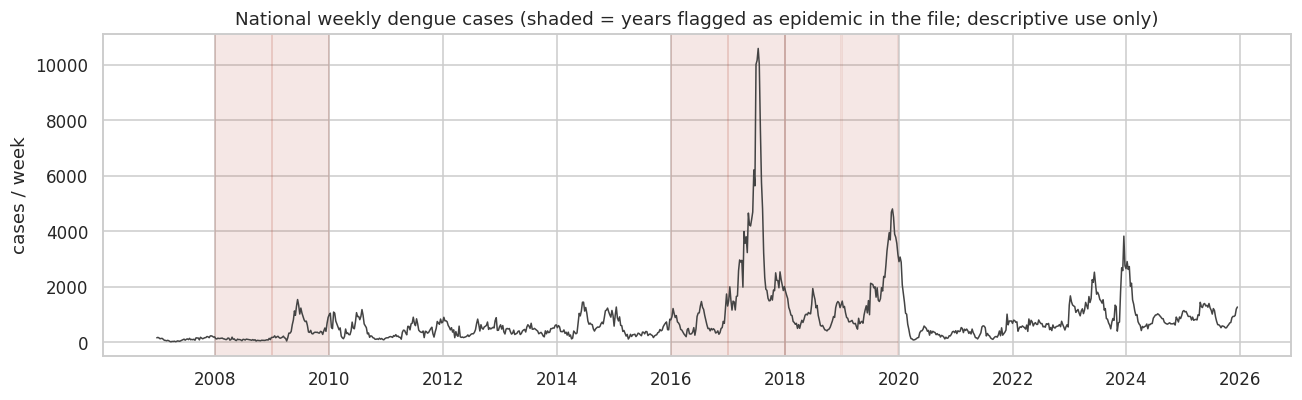

In [5]:
nat = df.groupby("date").agg(cases=("cases", "sum"), epi=("is_epidemic_year", "max"))
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(nat.index, nat.cases, color="#444", lw=1)
for y in nat[nat.epi == 1].index.year.unique(): ax.axvspan(pd.Timestamp(f"{y}-01-01"), pd.Timestamp(f"{y}-12-31"), color="#b3402a", alpha=.12)
ax.set_title("National weekly dengue cases (shaded = years flagged as epidemic in the file; descriptive use only)"); ax.set_ylabel("cases / week")
plt.tight_layout(); plt.savefig(FIG / "01_national_series.png", bbox_inches="tight"); plt.show()

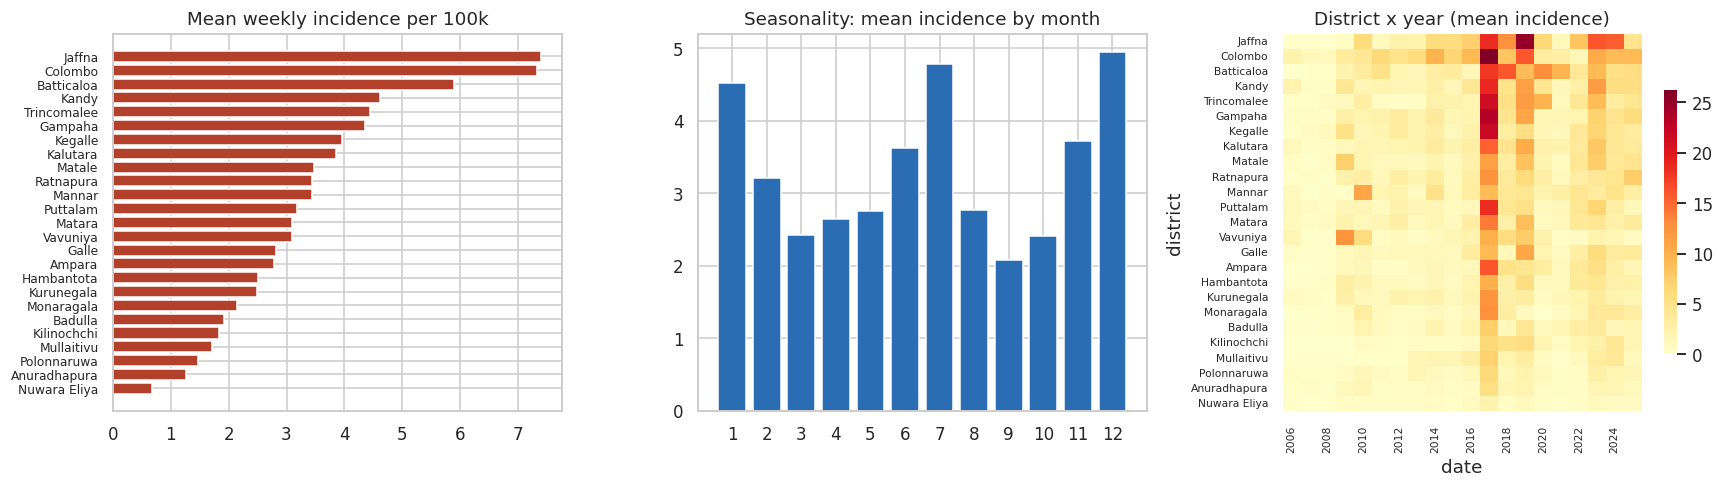

month means: {1: 4.5, 2: 3.2, 3: 2.4, 4: 2.7, 5: 2.8, 6: 3.6, 7: 4.8, 8: 2.8, 9: 2.1, 10: 2.4, 11: 3.7, 12: 5.0}


In [6]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
dm = df.groupby("district").incidence_rate.mean().sort_values()
ax[0].barh(dm.index, dm.values, color="#b3402a"); ax[0].set_title("Mean weekly incidence per 100k"); ax[0].tick_params(axis="y", labelsize=8)
mm = df.groupby(df.date.dt.month).incidence_rate.mean(); ax[1].bar(mm.index, mm.values, color="#2a6db3"); ax[1].set_xticks(range(1, 13)); ax[1].set_title("Seasonality: mean incidence by month")
hm = df.pivot_table(index="district", columns=df.date.dt.year, values="incidence_rate", aggfunc="mean").loc[dm.index[::-1]]
sns.heatmap(hm, cmap="YlOrRd", ax=ax[2], cbar_kws={"shrink": .7}, yticklabels=True); ax[2].set_title("District x year (mean incidence)"); ax[2].tick_params(axis="y", labelsize=7); ax[2].tick_params(axis="x", labelsize=7)
plt.tight_layout(); plt.savefig(FIG / "02_district_season_heatmap.png", bbox_inches="tight"); plt.show()
print("month means:", mm.round(1).to_dict())

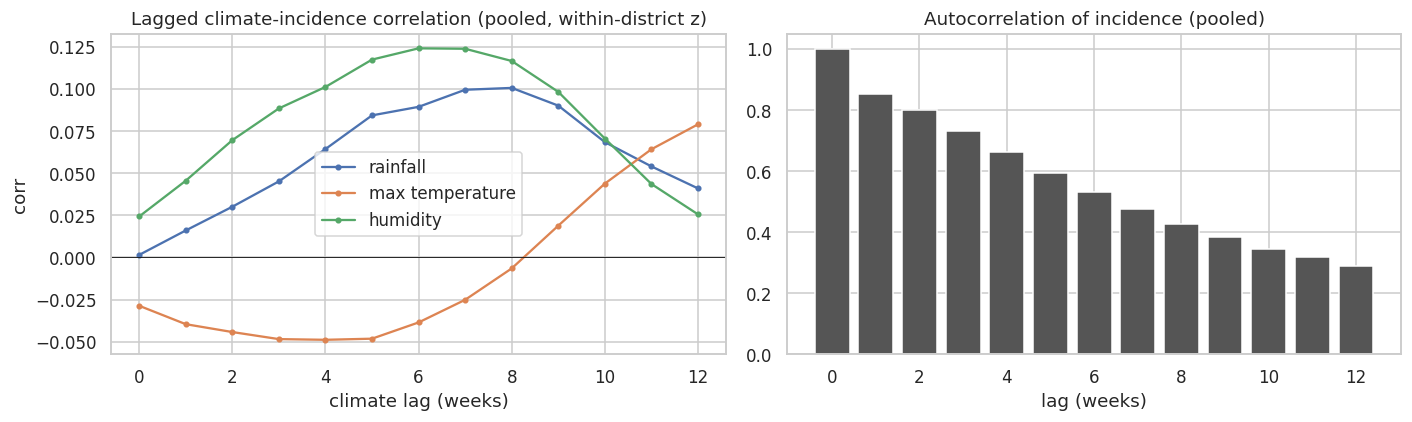

autocorr lag 1,2,4: [np.float64(0.85), np.float64(0.8), np.float64(0.66)]


In [7]:
# within-district z-scores so that big and small districts are comparable; correlation of incidence_t with climate_{t-lag}
dd = df.sort_values(["district", "date"]).copy()
z = lambda s: (s - s.mean()) / s.std()
dd["inc_z"] = dd.groupby("district").incidence_rate.transform(z)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for col, lab in {"rainfall_mm": "rainfall", "temp_max_c": "max temperature", "humidity_pct": "humidity"}.items():
    cz = dd.groupby("district")[col].transform(z)
    ax[0].plot(range(0, 13), [dd.inc_z.corr(cz.groupby(dd.district).shift(k)) for k in range(13)], marker="o", ms=3, label=lab)
ax[0].axhline(0, color="k", lw=.6); ax[0].set_xlabel("climate lag (weeks)"); ax[0].set_ylabel("corr"); ax[0].set_title("Lagged climate-incidence correlation (pooled, within-district z)"); ax[0].legend()
ac = [dd.inc_z.corr(dd.groupby("district").inc_z.shift(k)) for k in range(0, 13)]; ax[1].bar(range(13), ac, color="#555"); ax[1].set_title("Autocorrelation of incidence (pooled)"); ax[1].set_xlabel("lag (weeks)")
plt.tight_layout(); plt.savefig(FIG / "03_lagged_climate_acf.png", bbox_inches="tight"); plt.show()
print("autocorr lag 1,2,4:", [round(ac[k], 2) for k in (1, 2, 4)])

**What the EDA says**
* **Strong persistence:** pooled autocorrelation of incidence is 0.85 at lag 1, 0.80 at lag 2 and 0.66 at lag 4. Recent local history will dominate any model.
* **Seasonality:** mean incidence peaks in **June–July and again November–January**, with troughs in March–April and September–October, in line with the south-west and north-east monsoons.
* **Geography:** Colombo, Gampaha and Kandy carry most cases; the north has the lowest incidence. The district × year heatmap shows epidemic waves (2009, 2017, 2019, 2023) hitting many districts simultaneously.
* **Climate is weak but lagged:** within-district correlations with incidence peak at only ≈ 0.12 (humidity at ~6–7 weeks) and ≈ 0.10 (rainfall at ~7–8 weeks), which fits the mosquito life cycle but is small next to the 0.85 autocorrelation. We therefore expect climate to add little, and test it in section 9.5.

## 6. Supervised design, chronological split and inference sample
Row = (district, week *t*). Label = *incidence in week t + 2 exceeds that district's own training-period 75th percentile* ("a high week for that district"). A relative, per-district definition is used because an absolute national threshold would simply flag Colombo and Gampaha every week. The **latest week (all 25 districts)** is kept out of everything for single-sample inference; the earlier weeks are split chronologically 75/25 with a 2-week embargo.

In [8]:
S = dsl.build_supervised(df)
last_date = S.date.max()
infer = S[S.date == last_date].copy()                         # left-out week: all 25 districts
M = S[S.date < last_date]
mdates = np.sort(M.date.unique()); n_tr = int(len(mdates) * 0.75)
train = M[M.date.isin(mdates[:n_tr])].copy()
test = M[M.date.isin(mdates[n_tr + HORIZON:])].copy()          # 2-week embargo

now_inc = lambda t: t.cases_t / t.population * 1e5
BASE = train.assign(inc=now_inc(train)).groupby("district").inc.quantile(0.75)   # district 'high' level, TRAIN only
def prep(t):
    X = t.copy(); X["baseline_p75"] = X.district.map(BASE)
    y = (X.y_inc_next > X.baseline_p75).astype(int)
    return X[["district", "date"] + RAW_FIELDS], y
X_train, y_train = prep(train); X_test, y_test = prep(test); X_infer, y_infer = prep(infer)
print(f"train {len(X_train):,} rows  {X_train.date.min().date()} -> {X_train.date.max().date()}  high-week rate {y_train.mean():.1%}")
print(f"test  {len(X_test):,} rows  {X_test.date.min().date()} -> {X_test.date.max().date()}  high-week rate {y_test.mean():.1%}")
print(f"left-out week {X_infer.date.iloc[0].date()}: {len(X_infer)} districts, high-week rate {y_infer.mean():.0%}")
tscv = TimeSeriesSplit(n_splits=5, gap=HORIZON * 25)          # expanding window, never trains on the future
display(BASE.round(2).rename("district 'high' incidence level (per 100k)").to_frame().T)

train 18,375 rows  2007-02-10 -> 2021-03-06  high-week rate 24.9%
test  6,100 rows  2021-03-27 -> 2025-11-22  high-week rate 39.9%
left-out week 2025-11-29: 25 districts, high-week rate 68%


district,Ampara,Anuradhapura,Badulla,Batticaloa,Colombo,Galle,Gampaha,Hambantota,Jaffna,Kalutara,...,Matale,Matara,Monaragala,Mullaitivu,Nuwara Eliya,Polonnaruwa,Puttalam,Ratnapura,Trincomalee,Vavuniya
district 'high' incidence level (per 100k),2.25,1.45,1.85,6.31,9.5,2.48,4.15,2.93,7.29,3.8,...,3.26,3.36,1.78,2.08,0.82,1.83,2.78,3.79,3.32,3.45


## 7. Evaluation machinery (shared by every model, so the comparison is paired and fair)
Weeks are autocorrelated and districts share the same epidemic waves, so ordinary row-wise bootstrap would give far-too-narrow intervals. I resample **blocks of 4 consecutive calendar weeks** (all 25 districts together), and *reuse the same resamples for every model*, which also lets me test the **difference between Random Forest and XGBoost directly**.

In [9]:
def make_pipe(model, scale=False):
    steps = [("features", FunctionTransformer(add_derived))]
    if scale: steps.append(("scaler", StandardScaler()))
    return Pipeline(steps + [("model", model)])
FEAT = lambda X: X[RAW_FIELDS]           # models only see RAW_FIELDS (district/date are bookkeeping)

wk_codes, wk_uni = pd.factorize(X_test.date); W = len(wk_uni)
rows_by_week = [np.where(wk_codes == w)[0] for w in range(W)]
rng = np.random.default_rng(SEED); B = 400
BOOT = []
for _ in range(B):
    starts = rng.integers(0, W, int(np.ceil(W / 4)))
    wks = np.concatenate([(np.arange(s, s + 4)) % W for s in starts])[:W]
    BOOT.append(np.concatenate([rows_by_week[w] for w in wks]))
yt = y_test.values

def boot_stat(score_a, fn=roc_auc_score, score_b=None):
    out = []
    for idx in BOOT:
        if 0 < yt[idx].sum() < len(idx):
            out.append(fn(yt[idx], score_a[idx]) if score_b is None else fn(yt[idx], score_a[idx]) - fn(yt[idx], score_b[idx]))
    return np.percentile(out, [2.5, 97.5])

results, scores, cv_scores = {}, {}, {}
def evaluate(name, score, pred=None, thr=0.5):
    score = np.asarray(score); pred = (score >= thr).astype(int) if pred is None else pred
    lo, hi = boot_stat(score); scores[name] = score
    results[name] = dict(test_auc=roc_auc_score(yt, score), auc_lo=lo, auc_hi=hi, test_pr_auc=average_precision_score(yt, score),
                         recall=recall_score(yt, pred), precision=precision_score(yt, pred, zero_division=0), f1=f1_score(yt, pred),
                         accuracy=accuracy_score(yt, pred), brier=brier_score_loss(yt, np.clip(score, 0, 1)))
def cv_auc(pipe):
    s = []
    for tr, va in tscv.split(X_train):
        m = clone(pipe).fit(FEAT(X_train.iloc[tr]), y_train.iloc[tr]); s.append(roc_auc_score(y_train.iloc[va], m.predict_proba(FEAT(X_train.iloc[va]))[:, 1]))
    return np.mean(s), np.std(s)

## 8. Baselines: what an ensemble has to beat

In [10]:
models = {}
# persistence rule: "a district that is above its own usual-high level now will still be in two weeks"
rel_t = add_derived(FEAT(X_train)).rel_t.values; f = [roc_auc_score(y_train.iloc[v], rel_t[v]) for _, v in tscv.split(X_train)]
cv_scores["Persistence rule"] = (np.mean(f), np.std(f))
rel_te = add_derived(FEAT(X_test)).rel_t.values
evaluate("Persistence rule", rel_te, pred=(rel_te > 1).astype(int))

gs = GridSearchCV(make_pipe(LogisticRegression(class_weight="balanced", max_iter=3000), scale=True), {"model__C": [0.01, 0.1, 1, 10]}, cv=tscv, scoring="roc_auc").fit(FEAT(X_train), y_train)
models["Logistic Regression"] = gs.best_estimator_; cv_scores["Logistic Regression"] = (gs.best_score_, gs.cv_results_["std_test_score"][gs.best_index_])
evaluate("Logistic Regression", gs.predict_proba(FEAT(X_test))[:, 1]); print("logistic regression best:", gs.best_params_)

logistic regression best: {'model__C': 0.1}


## 8. Parameter engineering for Random Forest and XGBoost (no defaults)
With 18,375 correlated training rows (25 districts share the same epidemic waves) and 25% positives, the risks are over-fitting to individual waves and ignoring minority-class weeks. The search spaces are designed around that:

| Model | Hyper-parameter | Range | Reasoning |
|---|---|---|---|
| **Random Forest** | `max_depth` | 6–12 | deep enough for district × season interactions, shallow enough not to memorise one wave |
| | `min_samples_leaf` | 10–80 | every leaf must cover many district-weeks → smoother probabilities |
| | `max_features` | sqrt / 0.4 / 0.6 | decorrelates trees; many features are near-duplicates (`inc_t`, `rel_t`, means) |
| | `max_samples` | 0.4–0.8 | strong sub-sampling reduces correlation between trees |
| | `class_weight` | balanced(+subsample) | minority high weeks |
| | `n_estimators` | 150–400 | more trees only reduce variance |
| **XGBoost** | `learning_rate` × `n_estimators` | 0.02–0.1 × 200–700 | small steps, many trees |
| | `max_depth` | 3–8 | boosting wants weak learners |
| | `min_child_weight`, `gamma` | 3–30, 0–3 | refuse splits with little support |
| | `subsample`, `colsample_bytree` | 0.6–1, 0.5–0.9 | stochastic boosting |
| | `reg_lambda` | 1–20 | L2 shrinkage |
| | `scale_pos_weight` | 1–3 | class imbalance |

**Search:** randomised search (RF 12 draws, XGBoost 25 draws), scored by ROC-AUC with an **expanding-window `TimeSeriesSplit` (5 folds, gap = 2 weeks × 25 districts)**. Shuffled K-fold would let a model train on weeks *after* the ones it is validated on.

In [11]:
def tune(name, est, space, n_iter):
    t0 = time.time()
    rs = RandomizedSearchCV(make_pipe(est), {f"model__{k}": v for k, v in space.items()}, n_iter=n_iter, cv=tscv,
                            scoring="roc_auc", random_state=SEED, n_jobs=-1).fit(FEAT(X_train), y_train)
    models[name] = rs.best_estimator_; cv_scores[name] = (rs.best_score_, rs.cv_results_["std_test_score"][rs.best_index_])
    evaluate(name, rs.best_estimator_.predict_proba(FEAT(X_test))[:, 1])
    print(f"{name:14s} CV AUC {rs.best_score_:.3f} +/- {cv_scores[name][1]:.3f}  ({time.time()-t0:.0f}s)")
    print("   ", {k.replace("model__", ""): v for k, v in rs.best_params_.items()}); return rs

rf_space = dict(n_estimators=[150, 250, 400], max_depth=[6, 8, 10, 12], min_samples_leaf=[10, 20, 40, 80],
                max_features=["sqrt", 0.4, 0.6], max_samples=[0.4, 0.6, 0.8], class_weight=["balanced", "balanced_subsample"])
xgb_space = dict(n_estimators=[200, 400, 700], learning_rate=[0.02, 0.05, 0.1], max_depth=[3, 4, 6, 8],
                 min_child_weight=[3, 10, 30], subsample=[0.6, 0.8, 1.0], colsample_bytree=[0.5, 0.7, 0.9],
                 reg_lambda=[1, 5, 20], gamma=[0, 1, 3], scale_pos_weight=[1, 2, 3])
rs_rf = tune("Random Forest", RandomForestClassifier(random_state=SEED, n_jobs=1), rf_space, 12)
rs_xgb = tune("XGBoost", XGBClassifier(eval_metric="logloss", tree_method="hist", random_state=SEED, n_jobs=1), xgb_space, 25)

voting = make_pipe(VotingClassifier([("rf", clone(models["Random Forest"].named_steps["model"])), ("xgb", clone(models["XGBoost"].named_steps["model"]))], voting="soft"))
cv_scores["Soft Voting (RF+XGB)"] = cv_auc(voting); models["Soft Voting (RF+XGB)"] = voting.fit(FEAT(X_train), y_train)
evaluate("Soft Voting (RF+XGB)", voting.predict_proba(FEAT(X_test))[:, 1])
print(f"Soft voting CV AUC {cv_scores['Soft Voting (RF+XGB)'][0]:.3f}")

Random Forest  CV AUC 0.863 +/- 0.058  (375s)
    {'n_estimators': 400, 'min_samples_leaf': 20, 'max_samples': 0.6, 'max_features': 0.4, 'max_depth': 8, 'class_weight': 'balanced_subsample'}


XGBoost        CV AUC 0.866 +/- 0.061  (77s)
    {'subsample': 0.6, 'scale_pos_weight': 1, 'reg_lambda': 20, 'n_estimators': 700, 'min_child_weight': 3, 'max_depth': 3, 'learning_rate': 0.02, 'gamma': 0, 'colsample_bytree': 0.9}


Soft voting CV AUC 0.866


## 9. Head-to-head: Random Forest vs XGBoost
*Blue = Random Forest, red = XGBoost in every figure.*  
### 9.1 Full results table

,cv_auc_mean,cv_auc_std,test_auc,auc_lo,auc_hi,test_pr_auc,recall,precision,f1,accuracy,brier
Soft Voting (RF+XGB),0.866,0.059,0.877,0.852,0.899,0.828,0.767,0.742,0.754,0.800,0.140
Logistic Regression,0.866,0.055,0.872,0.848,0.894,0.815,0.819,0.702,0.756,0.789,0.153
XGBoost,0.866,0.061,0.875,0.850,0.898,0.825,0.681,0.783,0.728,0.797,0.140
Random Forest,0.863,0.058,0.876,0.852,0.898,0.827,0.854,0.677,0.755,0.779,0.151
Persistence rule,0.832,0.070,0.850,0.821,0.874,0.790,0.708,0.743,0.725,0.786,0.247


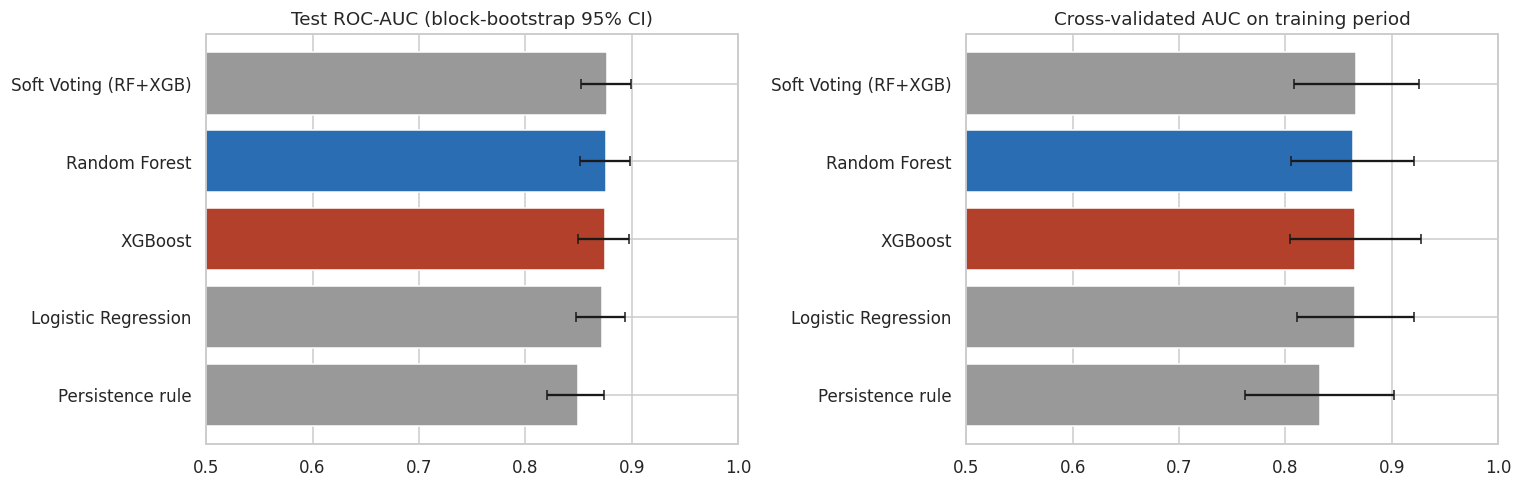

In [12]:
tbl = pd.DataFrame(results).T
tbl.insert(0, "cv_auc_mean", [cv_scores[k][0] for k in tbl.index]); tbl.insert(1, "cv_auc_std", [cv_scores[k][1] for k in tbl.index])
tbl = tbl.sort_values("cv_auc_mean", ascending=False)
display(tbl.round(3).style.format(precision=3).background_gradient(subset=["cv_auc_mean", "test_auc", "test_pr_auc"], cmap="YlGn"))
tbl.round(4).to_csv(FIG / "model_comparison.csv")
order_ = tbl.sort_values("test_auc").index
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
cols = lambda idx: [RF_C if "Random" in k else XG_C if k == "XGBoost" else "#999" for k in idx]
ax[0].barh(order_, tbl.loc[order_, "test_auc"], xerr=[tbl.loc[order_, "test_auc"] - tbl.loc[order_, "auc_lo"], tbl.loc[order_, "auc_hi"] - tbl.loc[order_, "test_auc"]], color=cols(order_), capsize=3)
ax[0].set_xlim(0.5, 1.0); ax[0].set_title("Test ROC-AUC (block-bootstrap 95% CI)")
ax[1].barh(order_, tbl.loc[order_, "cv_auc_mean"], xerr=tbl.loc[order_, "cv_auc_std"], color=cols(order_), capsize=3); ax[1].set_xlim(0.5, 1.0); ax[1].set_title("Cross-validated AUC on training period")
plt.tight_layout(); plt.savefig(FIG / "04_model_comparison.png", bbox_inches="tight"); plt.show()

### 9.2 ROC, precision-recall, confusion matrices and calibration

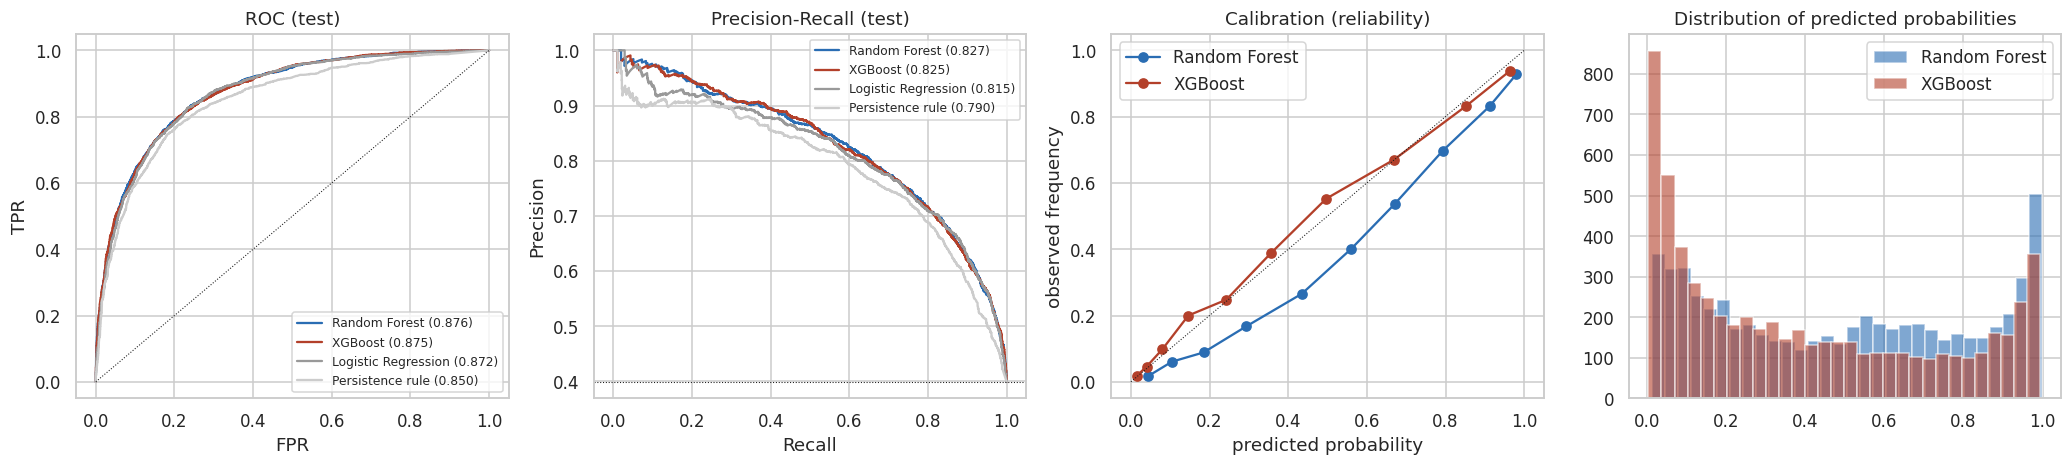

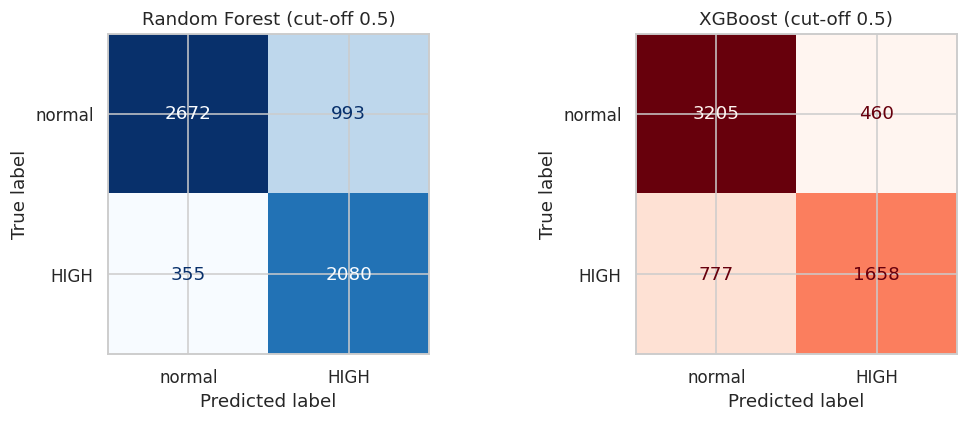

In [13]:
p_rf, p_xg = scores["Random Forest"], scores["XGBoost"]
fig, ax = plt.subplots(1, 4, figsize=(19, 4.4))
for nm, p, c in [("Random Forest", p_rf, RF_C), ("XGBoost", p_xg, XG_C), ("Logistic Regression", scores["Logistic Regression"], "#999"), ("Persistence rule", scores["Persistence rule"], "#ccc")]:
    fpr, tpr, _ = roc_curve(yt, p); ax[0].plot(fpr, tpr, color=c, label=f"{nm} ({results[nm]['test_auc']:.3f})")
    pr, rc, _ = precision_recall_curve(yt, p); ax[1].plot(rc, pr, color=c, label=f"{nm} ({results[nm]['test_pr_auc']:.3f})")
ax[0].plot([0, 1], [0, 1], "k:", lw=.7); ax[0].set_title("ROC (test)"); ax[0].set_xlabel("FPR"); ax[0].set_ylabel("TPR"); ax[0].legend(fontsize=8)
ax[1].axhline(yt.mean(), color="k", ls=":", lw=.7); ax[1].set_title("Precision-Recall (test)"); ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision"); ax[1].legend(fontsize=8)
for nm, p, c in [("Random Forest", p_rf, RF_C), ("XGBoost", p_xg, XG_C)]:
    fr, mp = calibration_curve(yt, p, n_bins=10, strategy="quantile"); ax[2].plot(mp, fr, marker="o", color=c, label=nm)
ax[2].plot([0, 1], [0, 1], "k:", lw=.7); ax[2].set_title("Calibration (reliability)"); ax[2].set_xlabel("predicted probability"); ax[2].set_ylabel("observed frequency"); ax[2].legend()
ax[3].hist(p_rf, bins=30, alpha=.6, color=RF_C, label="Random Forest"); ax[3].hist(p_xg, bins=30, alpha=.6, color=XG_C, label="XGBoost"); ax[3].set_title("Distribution of predicted probabilities"); ax[3].legend()
plt.tight_layout(); plt.savefig(FIG / "05_roc_pr_calibration.png", bbox_inches="tight"); plt.show()
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, nm, p in zip(ax, ["Random Forest", "XGBoost"], [p_rf, p_xg]):
    ConfusionMatrixDisplay.from_predictions(yt, (p >= .5).astype(int), display_labels=["normal", "HIGH"], cmap="Blues" if "Random" in nm else "Reds", ax=a, colorbar=False); a.set_title(f"{nm} (cut-off 0.5)")
plt.tight_layout(); plt.savefig(FIG / "06_confusion_rf_vs_xgb.png", bbox_inches="tight"); plt.show()

### 9.3 Do the two models agree? Is the difference real?

,value
label_agreement,0.8428
prob_pearson,0.9632
prob_spearman,0.9830
rf_only_correct,424.0000
xgb_only_correct,535.0000
mcnemar_p,0.0004
d_auc,0.0007
d_auc_lo,-0.0023
d_auc_hi,0.0043
d_pr,0.0012


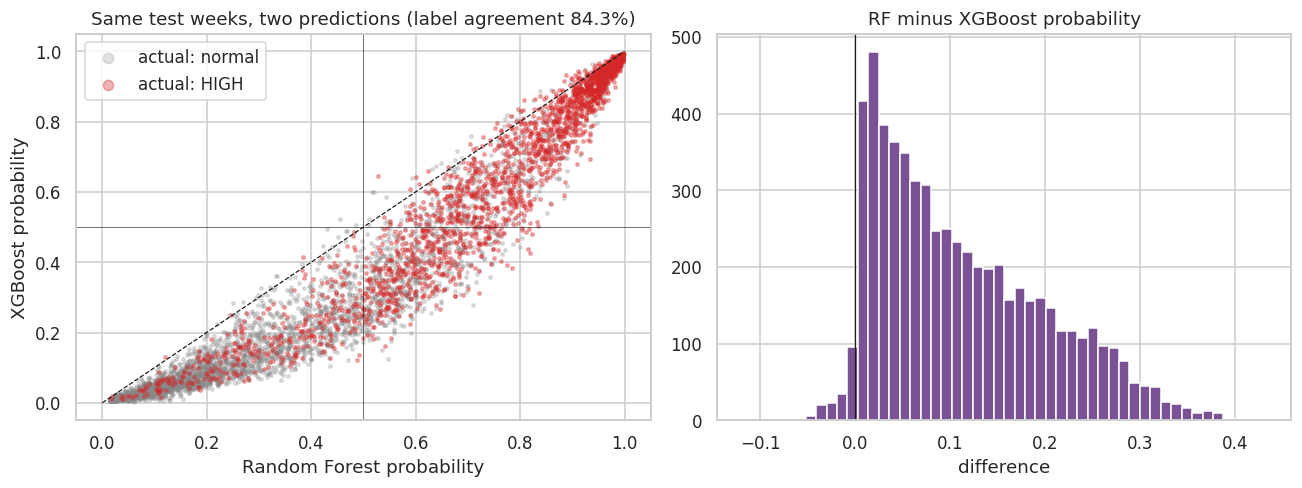

In [14]:
lab_rf, lab_xg = (p_rf >= .5).astype(int), (p_xg >= .5).astype(int)
agree = (lab_rf == lab_xg).mean()
rf_ok, xg_ok = lab_rf == yt, lab_xg == yt
b, c = int((rf_ok & ~xg_ok).sum()), int((~rf_ok & xg_ok).sum())          # discordant pairs
mcn = stats.binomtest(b, b + c, 0.5).pvalue if b + c else 1.0
d_auc = results["Random Forest"]["test_auc"] - results["XGBoost"]["test_auc"]; lo, hi = boot_stat(p_rf, roc_auc_score, p_xg)
d_pr = results["Random Forest"]["test_pr_auc"] - results["XGBoost"]["test_pr_auc"]; lo2, hi2 = boot_stat(p_rf, average_precision_score, p_xg)
cmp_ = dict(label_agreement=agree, prob_pearson=np.corrcoef(p_rf, p_xg)[0, 1], prob_spearman=stats.spearmanr(p_rf, p_xg)[0],
            rf_only_correct=b, xgb_only_correct=c, mcnemar_p=mcn, d_auc=d_auc, d_auc_lo=lo, d_auc_hi=hi, d_pr=d_pr, d_pr_lo=lo2, d_pr_hi=hi2)
display(pd.Series(cmp_).round(4).to_frame("value"))
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
ax[0].scatter(p_rf[yt == 0], p_xg[yt == 0], s=5, alpha=.25, color="#888", label="actual: normal"); ax[0].scatter(p_rf[yt == 1], p_xg[yt == 1], s=5, alpha=.35, color="#d62728", label="actual: HIGH")
ax[0].plot([0, 1], [0, 1], "k--", lw=.8); ax[0].axhline(.5, color="k", lw=.4); ax[0].axvline(.5, color="k", lw=.4)
ax[0].set_xlabel("Random Forest probability"); ax[0].set_ylabel("XGBoost probability"); ax[0].set_title(f"Same test weeks, two predictions (label agreement {agree:.1%})"); ax[0].legend(markerscale=3)
ax[1].hist(p_rf - p_xg, bins=50, color="#7a5195"); ax[1].axvline(0, color="k", lw=.8); ax[1].set_title("RF minus XGBoost probability"); ax[1].set_xlabel("difference")
plt.tight_layout(); plt.savefig(FIG / "07_rf_vs_xgb_agreement.png", bbox_inches="tight"); plt.show()

### 9.4 Where does each model win? (per district and per year)

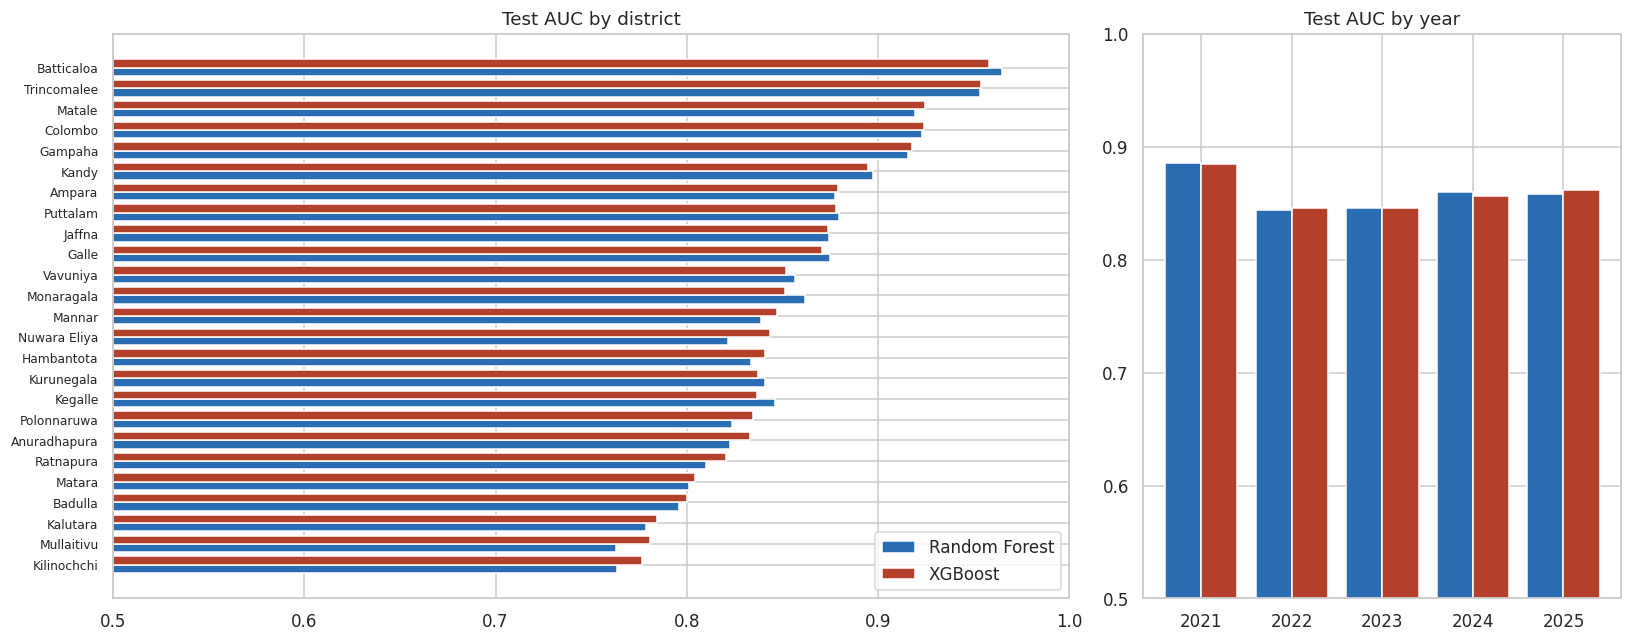

districts where RF > XGBoost: 9 of 25;  XGBoost > RF: 16


year,2021,2022,2023,2024,2025
RF,0.886,0.844,0.845,0.860,0.858
XGBoost,0.885,0.846,0.845,0.856,0.862
n,1000.000,1325.000,1300.000,1300.000,1175.000
high_rate,0.114,0.374,0.634,0.403,0.406


In [15]:
te = X_test[["district", "date"]].copy(); te["y"] = yt; te["rf"] = p_rf; te["xgb"] = p_xg; te["year"] = te.date.dt.year
def grp_auc(g): return pd.Series({"RF": roc_auc_score(g.y, g.rf), "XGBoost": roc_auc_score(g.y, g.xgb), "n": len(g), "high_rate": g.y.mean()}) if 0 < g.y.sum() < len(g) else None
by_d = te.groupby("district").apply(grp_auc).dropna().sort_values("XGBoost"); by_y = te.groupby("year").apply(grp_auc).dropna()
by_d.round(3).to_csv(FIG / "auc_by_district.csv"); by_y.round(3).to_csv(FIG / "auc_by_year.csv")
fig, ax = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [2, 1]})
yy = np.arange(len(by_d)); ax[0].barh(yy - .2, by_d.RF, .4, color=RF_C, label="Random Forest"); ax[0].barh(yy + .2, by_d.XGBoost, .4, color=XG_C, label="XGBoost")
ax[0].set_yticks(yy); ax[0].set_yticklabels(by_d.index, fontsize=8); ax[0].set_xlim(.5, 1); ax[0].set_title("Test AUC by district"); ax[0].legend()
xx = np.arange(len(by_y)); ax[1].bar(xx - .2, by_y.RF, .4, color=RF_C); ax[1].bar(xx + .2, by_y.XGBoost, .4, color=XG_C); ax[1].set_xticks(xx); ax[1].set_xticklabels(by_y.index); ax[1].set_ylim(.5, 1); ax[1].set_title("Test AUC by year")
plt.tight_layout(); plt.savefig(FIG / "08_auc_by_district_year.png", bbox_inches="tight"); plt.show()
w_ = (by_d.RF > by_d.XGBoost).sum(); print(f"districts where RF > XGBoost: {w_} of {len(by_d)};  XGBoost > RF: {len(by_d) - w_}")
display(by_y.round(3).T)

### 9.5 Alert cut-off trade-off and climate ablation

In [16]:
thr_rows = []
for t in (0.2, 0.3, 0.4, 0.5, 0.6, 0.7):
    for nm, p in (("Random Forest", p_rf), ("XGBoost", p_xg)):
        thr_rows.append({"cut-off": t, "model": nm, "recall": recall_score(yt, p >= t), "precision": precision_score(yt, p >= t, zero_division=0), "alerts": int((p >= t).sum())})
thr_tbl = pd.DataFrame(thr_rows).pivot(index="cut-off", columns="model"); display(thr_tbl.round(2)); thr_tbl.round(3).to_csv(FIG / "threshold_tradeoff.csv")

# fair comparison independent of each model's own probability scale: precision at equal recall, recall at equal precision
def at_recall(p, r0): pr_, rc_, _ = precision_recall_curve(yt, p); return float(pr_[rc_ >= r0].max())
def at_precision(p, p0): pr_, rc_, _ = precision_recall_curve(yt, p); return float(rc_[pr_ >= p0].max())
matched = pd.DataFrame({nm: {"precision @ recall 0.70": at_recall(p, .70), "precision @ recall 0.80": at_recall(p, .80), "precision @ recall 0.90": at_recall(p, .90),
                             "recall @ precision 0.70": at_precision(p, .70), "recall @ precision 0.80": at_precision(p, .80)} for nm, p in (("Random Forest", p_rf), ("XGBoost", p_xg))})
display(matched.round(3)); matched.round(4).to_csv(FIG / "matched_operating_points.csv")

def no_climate(X): return add_derived(X).drop(columns=CLIMATE_FIELDS)
abl = {}
for nm in ["Random Forest", "XGBoost"]:
    p = Pipeline([("features", FunctionTransformer(no_climate)), ("model", clone(models[nm].named_steps["model"]))])
    cvm = cv_auc(p); p.fit(FEAT(X_train), y_train); pr = p.predict_proba(FEAT(X_test))[:, 1]
    abl[nm] = dict(cv_with=cv_scores[nm][0], cv_without=cvm[0], test_with=results[nm]["test_auc"], test_without=roc_auc_score(yt, pr))
abl_df = pd.DataFrame(abl).T; display(abl_df.round(3)); abl_df.round(4).to_csv(FIG / "climate_ablation.csv")

recall             precision                alerts        
model   Random Forest XGBoost Random Forest XGBoost Random Forest XGBoost
cut-off                                                                  
0.2              0.97    0.91          0.53    0.61          4469    3596
0.3              0.93    0.85          0.58    0.68          3923    3037
0.4              0.90    0.76          0.63    0.73          3499    2529
0.5              0.85    0.68          0.68    0.78          3073    2118
0.6              0.76    0.59          0.74    0.82          2517    1756
0.7              0.65    0.51          0.80    0.86          1967    1426

,Random Forest,XGBoost
precision @ recall 0.70,0.774,0.775
precision @ recall 0.80,0.716,0.714
precision @ recall 0.90,0.626,0.619
recall @ precision 0.70,0.823,0.818
recall @ precision 0.80,0.655,0.647


,cv_with,cv_without,test_with,test_without
Random Forest,0.863,0.864,0.876,0.872
XGBoost,0.866,0.865,0.875,0.874


### Interpretation: Random Forest vs XGBoost

**1. In ranking skill they are statistically indistinguishable.**
| | Random Forest | XGBoost |
|---|---|---|
| CV AUC (train period, 5 folds) | 0.863 | 0.866 |
| Test ROC-AUC (95% CI) | 0.876 (0.852–0.899) | 0.875 (0.850–0.898) |
| Test PR-AUC | 0.827 | 0.826 |
| Paired AUC difference RF − XGB | **+0.0007, 95% CI −0.0023 to +0.0043** (includes 0) | |

The paired block-bootstrap interval for the difference straddles zero, and the PR-AUC difference (+0.0012, CI −0.004 to +0.008) does too. At **matched operating points they are the same**: precision at 80% recall is 0.716 (RF) vs 0.714 (XGB); recall at 70% precision is 0.823 vs 0.818. Per year the AUCs are within ±0.004 (2021–2025). Per district XGBoost is nominally ahead in 16 of 25 districts and RF in 9, by margins of at most about 0.02. **There is no evidence that either model is better at ranking risk.**

**2. They differ in *how their probabilities are scaled*, hence in behaviour at the default 0.5 cut-off.** The agreement scatter shows XGBoost's probabilities are an almost monotone, lower-shifted copy of RF's (Spearman 0.98, but RF is typically ~0.1 higher). At cut-off 0.5:
| | Recall | Precision | F1 | Accuracy | Brier (lower = better calibrated) |
|---|---|---|---|---|---|
| Random Forest | **0.854** | 0.677 | **0.755** | 0.779 | 0.151 |
| XGBoost | 0.681 | **0.783** | 0.728 | **0.797** | **0.140** |

RF is the more **alarmist** model (catches more high weeks, more false alarms); XGBoost is the more **conservative** and better-calibrated one. The models give the same label on 84.3% of test rows, and McNemar's test says their *errors at 0.5* differ (p = 0.0004: XGBoost is the only correct one on 535 rows, RF on 424). That difference comes from the probability scale (balanced class weights in RF vs none in XGBoost), not from better ranking, and moving the cut-off (table above) trades one for the other: **RF at cut-off 0.6 (recall 0.76, precision 0.74) is practically XGBoost at cut-off 0.4 (recall 0.76, precision 0.73)**. For public health, where a missed surge costs more than a false alarm, RF's default operating point is arguably the safer one; for scarce-resource targeting, XGBoost's is.

**3. Neither is much better than simpler approaches.** Logistic regression reaches CV AUC 0.866 and test AUC 0.872, equal to both ensembles; soft voting (RF+XGB) gives 0.877. The persistence rule ("a district above its usual-high level now stays high") already reaches 0.850. So the ensembles add only about **+0.025 AUC over a one-line rule** and nothing measurable over a well-regularised linear model. This is a property of the data: autocorrelation of 0.85 leaves little room for non-linearity to help. This is the honest result to report, not a reason to inflate the ensembles.

**4. Climate adds nothing measurable** (ablation): removing the six climate features changes CV AUC from 0.863 to 0.864 (RF) and 0.866 to 0.865 (XGBoost), and test AUC by less than 0.005.

**Strengths and limitations observed here**
| | Random Forest | XGBoost |
|---|---|---|
| Strengths | stable, almost no tuning sensitivity; higher recall at 0.5; 12 draws were enough | better calibrated (Brier 0.140); best CV AUC by a hair; 5× faster to tune (77 s vs 365 s); 10× smaller pickle (0.8 MB vs 8.5 MB) |
| Limitations | probabilities inflated (~0.1) unless re-calibrated; large model file; slow to tune; SHAP slower | more hyper-parameters; default 0.5 cut-off misses 32% of high weeks; sensitive to `scale_pos_weight` choice |

## 10. Explainability: SHAP for both models
SHAP is computed on a random sample of 500 test rows for the tuned RF and XGBoost (RF values are in probability units, XGBoost in log-odds, so importances are compared as *shares*).

SHAP done in 5s


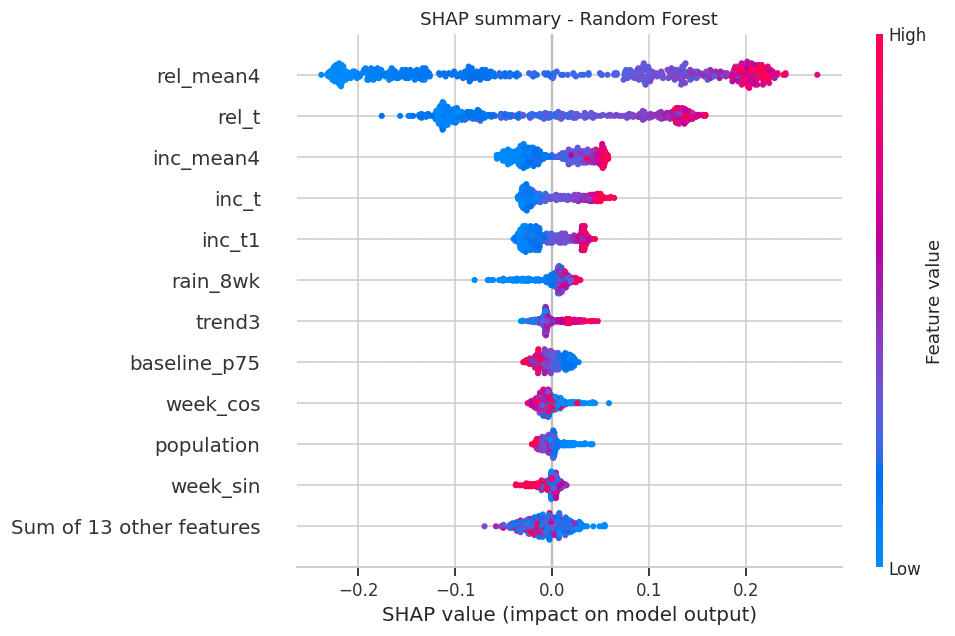

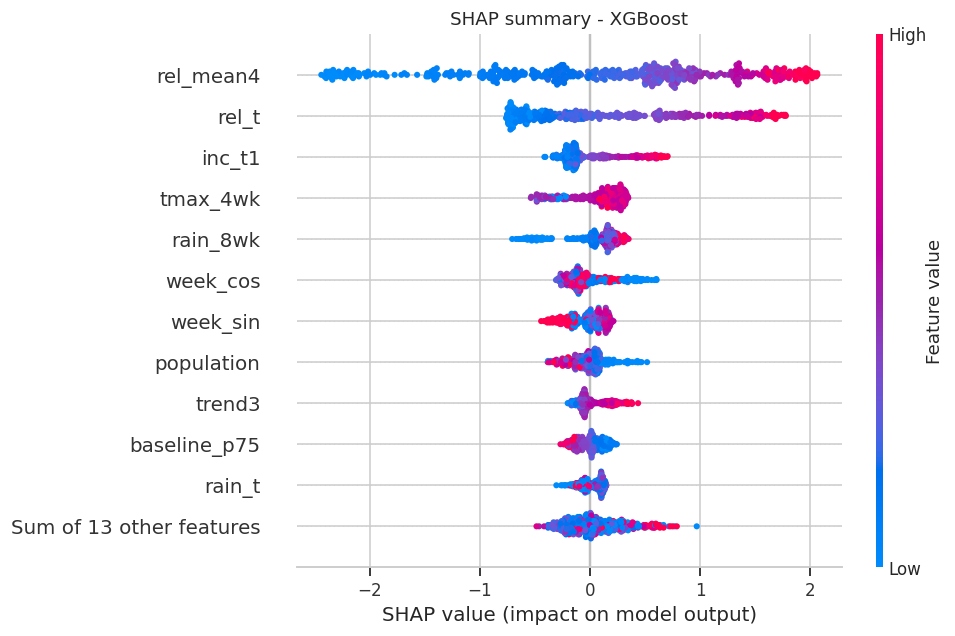

In [17]:
def tree_shap(pipe, X):
    Xf = pipe.named_steps["features"].transform(X)
    sv = shap.TreeExplainer(pipe.named_steps["model"])(Xf, check_additivity=False)
    return Xf, (sv[:, :, 1] if sv.values.ndim == 3 else sv)
samp = X_test.sample(500, random_state=SEED)
t0 = time.time(); Xf_s, sv_rf = tree_shap(models["Random Forest"], FEAT(samp)); _, sv_xgb = tree_shap(models["XGBoost"], FEAT(samp)); print(f"SHAP done in {time.time()-t0:.0f}s")
for nm, sv, fn in [("Random Forest", sv_rf, "09_shap_rf.png"), ("XGBoost", sv_xgb, "10_shap_xgb.png")]:
    plt.figure(); shap.plots.beeswarm(sv, max_display=12, show=False); plt.title(f"SHAP summary - {nm}"); plt.savefig(FIG / fn, bbox_inches="tight"); plt.show()

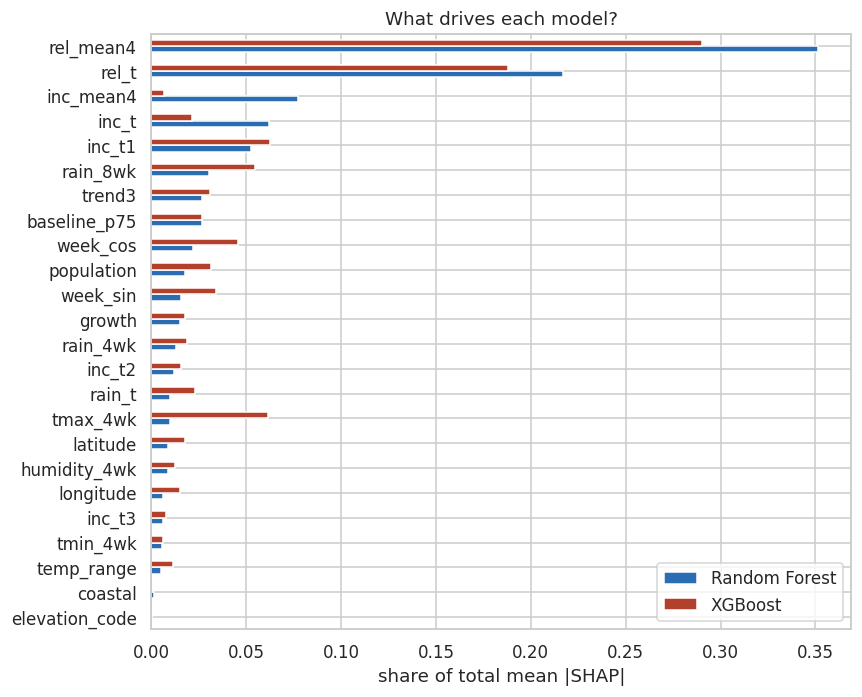

combined SHAP share of climate features: {'Random Forest': 8.2, 'XGBoost': 18.8}
Spearman rank agreement of the two importance rankings: 0.73
top 5 RF : {'rel_mean4': 0.351, 'rel_t': 0.217, 'inc_mean4': 0.077, 'inc_t': 0.062, 'inc_t1': 0.053}
top 5 XGB: {'rel_mean4': 0.29, 'rel_t': 0.188, 'inc_t1': 0.063, 'tmax_4wk': 0.061, 'rain_8wk': 0.055}


In [18]:
imp = pd.DataFrame({"Random Forest": np.abs(sv_rf.values).mean(0), "XGBoost": np.abs(sv_xgb.values).mean(0)}, index=Xf_s.columns)
imp = (imp / imp.sum()).sort_values("Random Forest")
imp.plot.barh(figsize=(8, 6.5), color=[RF_C, XG_C]); plt.xlabel("share of total mean |SHAP|"); plt.title("What drives each model?"); plt.tight_layout()
plt.savefig(FIG / "11_shap_importance_compare.png", bbox_inches="tight"); plt.show()
clim = [c for c in imp.index if c in CLIMATE_FIELDS]
print("combined SHAP share of climate features:", (imp.loc[clim].sum() * 100).round(1).to_dict())
print("Spearman rank agreement of the two importance rankings:", round(stats.spearmanr(imp["Random Forest"], imp["XGBoost"])[0], 2))
print("top 5 RF :", imp["Random Forest"].sort_values(ascending=False).head(5).round(3).to_dict()); print("top 5 XGB:", imp["XGBoost"].sort_values(ascending=False).head(5).round(3).to_dict())
imp.round(4).to_csv(FIG / "shap_importance.csv")

### What SHAP shows
* **Both models rely on the same thing:** the district's recent incidence *relative to its own usual-high level*. `rel_mean4` (average of the last 4 weeks ÷ baseline) is the top driver in both (35% of RF's and 29% of XGBoost's total attribution), followed by `rel_t` (22% / 19%) and the individual lagged incidences. Raw level without context matters much less, which validates the district-relative design.
* **Agreement:** the two importance rankings correlate at Spearman 0.73. They agree on the top drivers and differ in the tail: XGBoost spreads more attribution over climate (≈19% in total vs ≈8% for RF).
* **Climate is used, but not needed.** XGBoost gives temperature and rainfall means noticeable attribution, yet the ablation shows removing them does not hurt. SHAP shows what a model *uses*, not what *helps* out of sample; the two analyses must be read together.
* **Season** (`week_sin`, `week_cos`) and static geography (`longitude`, `population`) play minor roles.

## 11. Single-sample inference: both models on the left-out week
The newest week in the file (all 25 districts) was never used for training, tuning or testing. Both models are refit on **all** modelling weeks (same tuned hyper-parameters) and predict every district.

Input week starting 2025-11-29  ->  prediction for week starting 2025-12-13


,actual_cases_in_2wk,actual_high,RF,XGBoost,RF_label,XGB_label,agree
district,,,,,,,
Galle,82.0,1,0.960,0.956,HIGH,HIGH,True
Gampaha,214.0,1,0.952,0.948,HIGH,HIGH,True
Jaffna,76.0,1,0.866,0.839,HIGH,HIGH,True
Matara,44.0,1,0.853,0.838,HIGH,HIGH,True
Ratnapura,60.0,1,0.865,0.808,HIGH,HIGH,True
Colombo,340.0,1,0.806,0.789,HIGH,HIGH,True
Monaragala,24.0,1,0.763,0.774,HIGH,HIGH,True
Kalutara,85.0,1,0.831,0.740,HIGH,HIGH,True
Kilinochchi,5.0,1,0.733,0.726,HIGH,HIGH,True


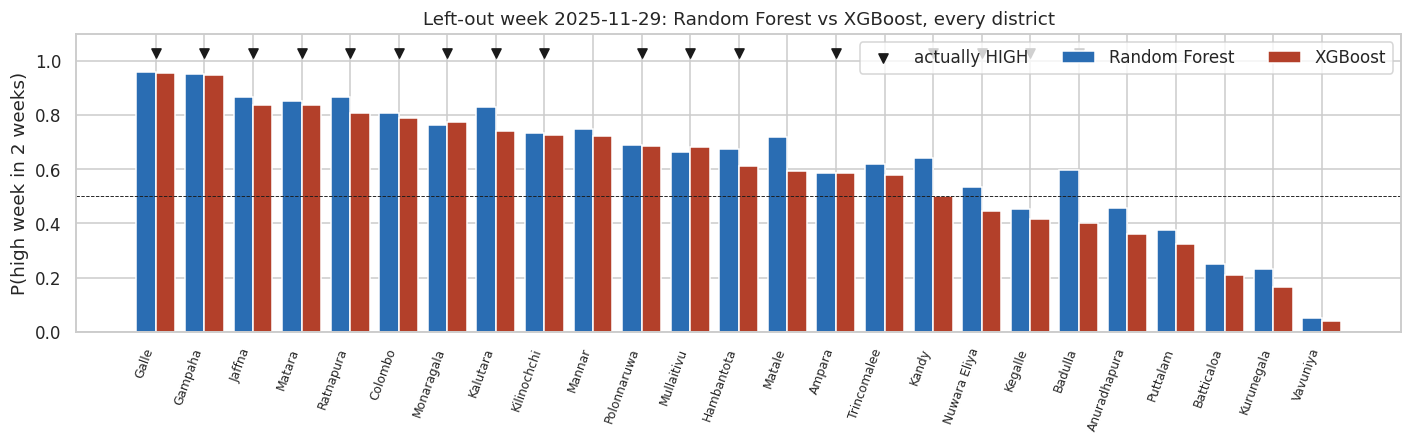

accuracy on the 25 unseen district-weeks:  RF 84%   XGBoost 76%;  models agree on 92%


In [19]:
y_m = pd.concat([y_train, y_test]); X_m = pd.concat([X_train, X_test])
full = {k: clone(models[k]).fit(FEAT(X_m), y_m) for k in ["Random Forest", "XGBoost"]}
inf = X_infer[["district", "date"]].copy(); inf["actual_cases_in_2wk"] = infer.y_cases_next.values.round(0); inf["actual_high"] = y_infer.values
inf["RF"] = full["Random Forest"].predict_proba(FEAT(X_infer))[:, 1]; inf["XGBoost"] = full["XGBoost"].predict_proba(FEAT(X_infer))[:, 1]
inf["RF_label"] = np.where(inf.RF >= .5, "HIGH", "normal"); inf["XGB_label"] = np.where(inf.XGBoost >= .5, "HIGH", "normal"); inf["agree"] = inf.RF_label == inf.XGB_label
inf = inf.sort_values("XGBoost", ascending=False)
print(f"Input week starting {X_infer.date.iloc[0].date()}  ->  prediction for week starting {(X_infer.date.iloc[0] + pd.Timedelta(weeks=HORIZON)).date()}")
display(inf.drop(columns="date").round(3).set_index("district"))
inf.round(4).to_csv(FIG / "inference_all_districts.csv", index=False)
fig, ax = plt.subplots(figsize=(13, 4.2)); xx = np.arange(len(inf))
ax.bar(xx - .2, inf.RF, .4, color=RF_C, label="Random Forest"); ax.bar(xx + .2, inf.XGBoost, .4, color=XG_C, label="XGBoost")
ax.scatter(xx[inf.actual_high.values == 1], np.full(int(inf.actual_high.sum()), 1.03), marker="v", color="k", label="actually HIGH", zorder=3)
ax.axhline(.5, color="k", lw=.6, ls="--"); ax.set_xticks(xx); ax.set_xticklabels(inf.district, rotation=70, ha="right", fontsize=8); ax.set_ylim(0, 1.1)
ax.set_ylabel("P(high week in 2 weeks)"); ax.set_title(f"Left-out week {X_infer.date.iloc[0].date()}: Random Forest vs XGBoost, every district"); ax.legend(ncol=3)
plt.tight_layout(); plt.savefig(FIG / "12_inference_all_districts.png", bbox_inches="tight"); plt.show()
ok = lambda c: ((inf[c] >= .5).astype(int) == inf.actual_high).mean()
print(f"accuracy on the 25 unseen district-weeks:  RF {ok('RF'):.0%}   XGBoost {ok('XGBoost'):.0%};  models agree on {inf.agree.mean():.0%}")

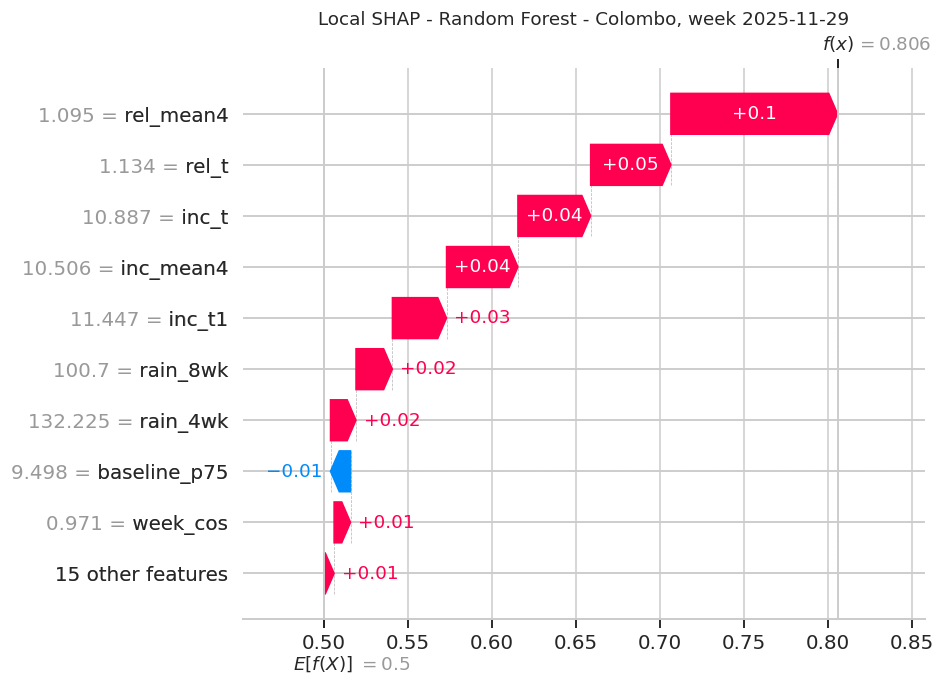

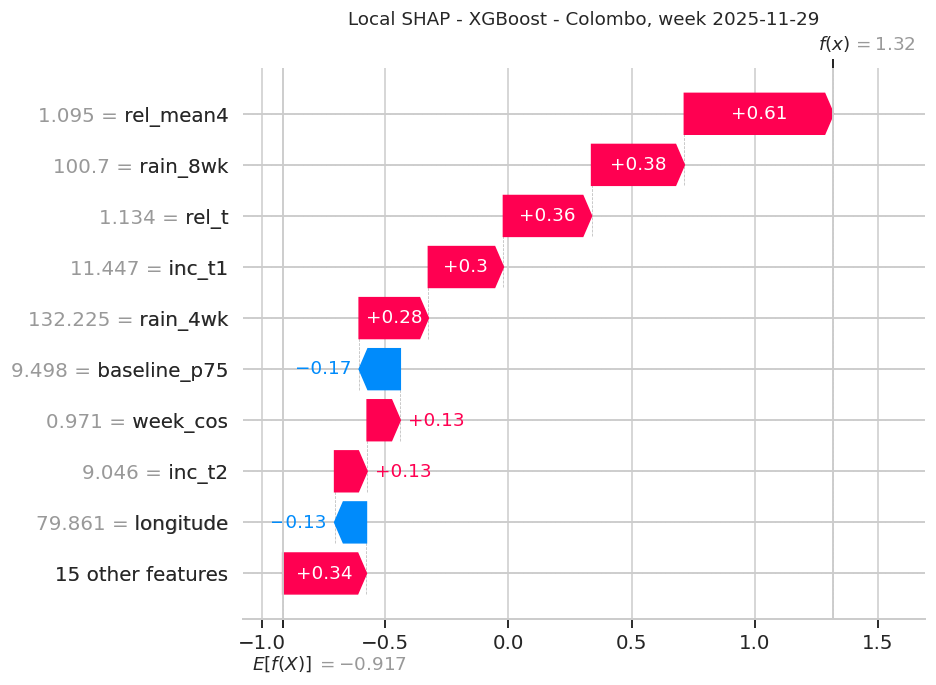

,24529
district,Colombo
date,2025-11-29 00:00:00
epi_week,50
cases_t,272.0
cases_t1,286.0
cases_t2,226.0
cases_t3,266.0
rain_t,17.9
rain_4wk,132.225
rain_8wk,100.7


In [20]:
# local SHAP for Colombo, both models
ci = list(X_infer.district).index("Colombo")
fig_i = 13
for k, pp in full.items():
    _, sv_i = tree_shap(pp, FEAT(X_infer.iloc[[ci]]))
    plt.figure(); shap.plots.waterfall(sv_i[0], max_display=10, show=False); plt.title(f"Local SHAP - {k} - Colombo, week {X_infer.date.iloc[0].date()}")
    plt.savefig(FIG / f"{fig_i}_shap_waterfall_{k.split()[0].lower()}.png", bbox_inches="tight"); plt.show(); fig_i += 1
display(X_infer.iloc[[ci]][["district", "date"] + DYNAMIC].T)

### Reading the single-sample inference
For the newest week in the file (starting **29 Nov 2025**, predicting the week of 13 Dec 2025) both models were run on all 25 districts. **Colombo: RF 81%, XGBoost 79%, both HIGH, and the actual outcome was 340 cases (HIGH).** 17 of 25 district-weeks were actually high (68%), a national surge. The models agree on the label for 92% of districts; RF classified 84% of the 25 unseen district-weeks correctly and XGBoost 76%, but with only 25 rows from a single week this gap is anecdotal. It mirrors the behaviour in section 9: RF's lower cut-off catches more of a surge, XGBoost is more cautious.

The XGBoost waterfall for Colombo shows why: a 4-week average slightly above the district's high level (`rel_mean4` = 1.09), heavy 8-week rainfall (101 mm), and this week's incidence above baseline (`rel_t` = 1.13) all push the score up, with the baseline itself and longitude pulling slightly down.

## 12. Export both models (`.pkl`) and metadata for the web app

In [21]:
(ROOT / "models").mkdir(exist_ok=True)
for k, fn in [("Random Forest", "rf_model.pkl"), ("XGBoost", "xgb_model.pkl")]:
    with open(ROOT / "models" / fn, "wb") as f: pickle.dump(full[k], f)

# --- real example weeks for the app (chosen from the TEST period with the train-only models) ---
pr = te.assign(dis=(te.rf - te.xgb).abs()); both = (te.rf >= .5) & (te.xgb >= .5) & (te.y == 1); quiet = (te.rf < .5) & (te.xgb < .5) & (te.y == 0)
def example(idx, label, note):
    r = X_test.loc[X_test.index[idx]]; t = test.loc[test.index[idx]]
    return dict(label=label, district=r.district, week_start=str(r.date.date()), inputs={k: round(float(r[k]), 2) for k in DYNAMIC + ["population"]},
                outcome=f"{note}: {int(t.y_cases_next)} cases 2 weeks later, {'HIGH' if te.y.iloc[idx] else 'normal'} week")
i_hit = int(np.argmax(np.where(both, np.minimum(te.rf, te.xgb), -1))); i_quiet = int(np.argmin(np.where(quiet, np.maximum(te.rf, te.xgb), 9)))
i_dis = int(np.argmax(pr.dis.values))
examples = [example(i_hit, "Rising week - both models alarm", "real test week"), example(i_quiet, "Quiet week - both models calm", "real test week"),
            example(i_dis, "Disagreement - RF and XGBoost differ most", "real test week")]
r = X_infer.iloc[ci]; examples.append(dict(label="Colombo, newest week (left out)", district="Colombo", week_start=str(r.date.date()),
    inputs={k: round(float(r[k]), 2) for k in DYNAMIC + ["population"]}, outcome=f"left-out week: {int(infer.y_cases_next.iloc[ci])} cases 2 weeks later, {'HIGH' if y_infer.iloc[ci] else 'normal'} week"))

dist_tbl = {}
last = df[df.date == df.date.max()].set_index("district")
for dname, g in df.groupby("district"):
    dist_tbl[dname] = dict(population=int(last.loc[dname, "population"]), latitude=float(g.latitude.iloc[0]), longitude=float(g.longitude.iloc[0]), coastal=int(g.coastal_district.iloc[0]),
                           elevation_code=int(g.elevation_code.iloc[0]), baseline_p75=float(BASE[dname]), province=g.province.iloc[0])
meta = dict(horizon_weeks=HORIZON, dynamic_fields=DYNAMIC, static_fields=STATIC, raw_fields=RAW_FIELDS, districts=dist_tbl, examples=examples,
            data_range=[str(df.date.min().date()), str(df.date.max().date())], test_range=[str(X_test.date.min().date()), str(X_test.date.max().date())],
            field_ranges={c: dict(min=float(X_m[c].min()), median=float(X_m[c].median()), max=float(X_m[c].max())) for c in DYNAMIC},
            metrics={k: {m: round(float(v), 4) for m, v in results[k].items()} for k in ["Random Forest", "XGBoost"]},
            cv_auc={k: round(float(cv_scores[k][0]), 4) for k in ["Random Forest", "XGBoost"]},
            comparison={k: round(float(v), 4) for k, v in cmp_.items()}, matched=matched.round(4).to_dict(), high_week_definition="incidence 2 weeks ahead > district's training-period 75th percentile")
json.dump(meta, open(ROOT / "models" / "model_meta.json", "w"), indent=1)

with open(ROOT / "models" / "rf_model.pkl", "rb") as f1, open(ROOT / "models" / "xgb_model.pkl", "rb") as f2: rl, xl = pickle.load(f1), pickle.load(f2)
print("reload check  RF:", np.allclose(rl.predict_proba(FEAT(X_infer))[:, 1], inf.sort_index().RF.reindex(X_infer.index).values if False else full["Random Forest"].predict_proba(FEAT(X_infer))[:, 1]),
      "| XGB:", np.allclose(xl.predict_proba(FEAT(X_infer))[:, 1], full["XGBoost"].predict_proba(FEAT(X_infer))[:, 1]))
print("sizes (KB):", {fn: round((ROOT / "models" / fn).stat().st_size / 1024) for fn in ["rf_model.pkl", "xgb_model.pkl"]})
print({e["label"]: (e["district"], e["week_start"], e["outcome"]) for e in examples})

reload check  RF: True | XGB: True
sizes (KB): {'rf_model.pkl': 8481, 'xgb_model.pkl': 807}
{'Rising week - both models alarm': ('Ratnapura', '2025-05-03', 'real test week: 203 cases 2 weeks later, HIGH week'), 'Quiet week - both models calm': ('Matale', '2021-04-03', 'real test week: 2 cases 2 weeks later, normal week'), 'Disagreement - RF and XGBoost differ most': ('Trincomalee', '2024-03-09', 'real test week: 12 cases 2 weeks later, normal week'), 'Colombo, newest week (left out)': ('Colombo', '2025-11-29', 'left-out week: 340 cases 2 weeks later, HIGH week')}


## 13. Front end (GenAI-generated Streamlit app) and deployment
`streamlit_app.py` loads **both** pickles and, for one district and one week, shows **side by side**: the Random Forest probability, the XGBoost probability, their difference, an agreement / disagreement banner, a probability bar chart, and a *why* chart for each model (SHAP for RF, native contributions for XGBoost). A second tab shows the held-out comparison (table, ROC/PR/calibration, agreement scatter, per-district AUC, SHAP comparison). Four real example weeks can be loaded with one click, including one where the models disagree. The prompt used is in `prompts/frontend_prompt.md`.

```bash
pip install -r requirements.txt
streamlit run streamlit_app.py
```
Deploy on Streamlit Community Cloud with main file `streamlit_app.py` and **Python 3.12** (see README).

## 14. Conclusions, limitations and next steps
**Conclusions**
1. Both tuned models predict a high-incidence week two weeks ahead with **AUC ≈ 0.875** across 25 districts and 4.7 unseen years, versus 0.850 for a persistence rule.
2. **Random Forest and XGBoost are equivalent in ranking skill** (paired AUC difference +0.0007, CI includes 0; identical precision at matched recall). They differ in probability scale: RF is more alarmist (recall 0.85, precision 0.68), XGBoost more conservative and better calibrated (recall 0.68, precision 0.78). Choose by the cost of a missed surge versus a false alarm, or recalibrate and set the cut-off explicitly.
3. Ensembles do **not** measurably beat a regularised logistic regression on this data; recent local incidence relative to the district baseline carries almost all the signal, and climate adds nothing measurable.
4. SHAP explanations of the two models agree on the main drivers, which makes the explanation trustworthy.

**Limitations.** One chronological split; districts are spatially and temporally correlated (block bootstrap mitigates but does not remove this); notified cases are not true incidence; 2007–2008 look under-reported and 2012/2016/2022 contain reporting gaps beyond the zeros we repaired; district population is partly *predicted*; the data source is not documented in the file.

**Next steps.** Probability calibration (isotonic) so both models can share one cut-off; spatial-neighbour features (cases in adjacent districts); LightGBM/CatBoost and stacking; quantile or count regression for expected cases; rolling-origin evaluation across several test windows; counterfactual explanations (DiCE).

*Reproducibility: seeds fixed (42); library versions in `requirements.txt`.*